In [3]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

In [4]:
dataset_dir = "C:/Users/sanja/Desktop/AD_DATASET/Data"
classes = ["Mild Dementia", "Moderate Dementia", "Non Demented", "Very mild Dementia"]

image_paths, labels = [], []

for class_label, class_name in enumerate(classes):
    class_dir = os.path.join(dataset_dir, class_name)
    files = glob.glob(f"{class_dir}/*.jpg")
    print(f"{class_name}: {len(files)} files")
    for file_path in files:
        image_paths.append(file_path)
        labels.append(class_label)

if len(image_paths) == 0:
    raise ValueError("No images found. Check dataset path.")

Mild Dementia: 5002 files
Moderate Dementia: 488 files
Non Demented: 67222 files
Very mild Dementia: 13725 files


In [5]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, random_state=42, stratify=labels)

label_binarizer = LabelBinarizer()
train_labels = label_binarizer.fit_transform(train_labels)
test_labels = label_binarizer.transform(test_labels)

train_paths = np.array(train_paths)
test_paths = np.array(test_paths)

In [6]:
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32

def preprocess_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = tf.keras.applications.resnet.preprocess_input(image)
    return image

def load_dataset(image_paths, labels):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    dataset = dataset.map(lambda x, y: (preprocess_image(x), y),
                          num_parallel_calls=tf.data.AUTOTUNE)
    return dataset

train_dataset = load_dataset(train_paths, train_labels)
test_dataset = load_dataset(test_paths, test_labels)

train_dataset = train_dataset.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [7]:
base_model = tf.keras.applications.ResNet50(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3))

base_model.trainable = False  # Freeze all layers

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(4, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step 


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [8]:
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10
)

Epoch 1/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2551s 1s/step - accuracy: 0.8039 - loss: 0.4642 - val_accuracy: 0.8120 - val_loss: 0.4183
Epoch 2/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2443s 1s/step - accuracy: 0.8425 - loss: 0.3618 - val_accuracy: 0.8729 - val_loss: 0.2966
Epoch 3/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2452s 1s/step - accuracy: 0.8637 - loss: 0.3112 - val_accuracy: 0.8772 - val_loss: 0.2846
Epoch 4/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2457s 1s/step - accuracy: 0.8836 - loss: 0.2711 - val_accuracy: 0.9158 - val_loss: 0.2235
Epoch 5/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2473s 1s/step - accuracy: 0.8992 - loss: 0.2361 - val_accuracy: 0.9187 - val_loss: 0.1994
Epoch 6/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2476s 1s/step - accuracy: 0.9057 - loss: 0.2218 - val_accuracy: 0.9415 - val_loss: 0.1581
Epoch 7/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2473s 1s/step - accuracy: 0.9136 - loss: 0.2048 - val_accuracy: 0.9385 - val_loss: 0.1535
Epoch 8/10
2161/2161 ━━━━━━━━━━━━━━━━━━━━ 2476s 1s/step - accuracy: 0.9178 -

In [9]:
loss, acc = model.evaluate(test_dataset)
print(f"\nTest Accuracy: {acc * 100:.2f}%")

# Get predictions
y_true = np.argmax(np.vstack([y for x, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=classes))

541/541 ━━━━━━━━━━━━━━━━━━━━ 492s 910ms/step - accuracy: 0.9530 - loss: 0.1241

Test Accuracy: 95.30%
541/541 ━━━━━━━━━━━━━━━━━━━━ 496s 913ms/step
                    precision    recall  f1-score   support

     Mild Dementia       0.93      0.85      0.89      1000
 Moderate Dementia       0.97      0.89      0.93        98
      Non Demented       0.97      0.98      0.97     13445
Very mild Dementia       0.88      0.87      0.88      2745

          accuracy                           0.95     17288
         macro avg       0.94      0.90      0.92     17288
      weighted avg       0.95      0.95      0.95     17288



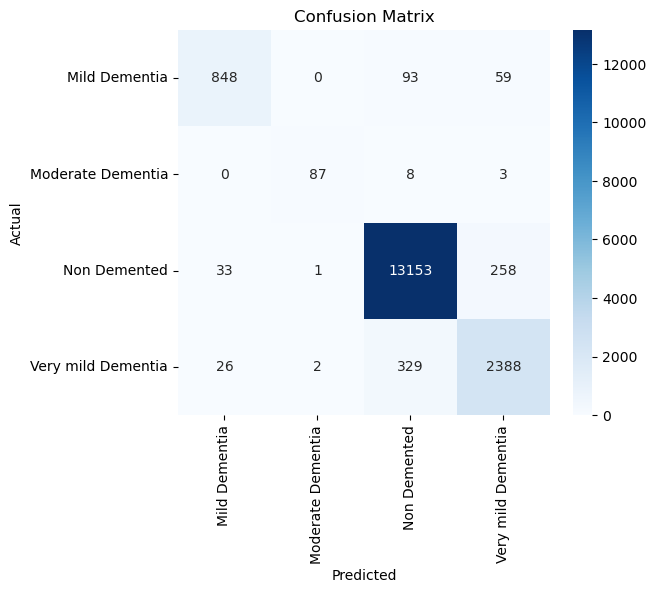

In [10]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

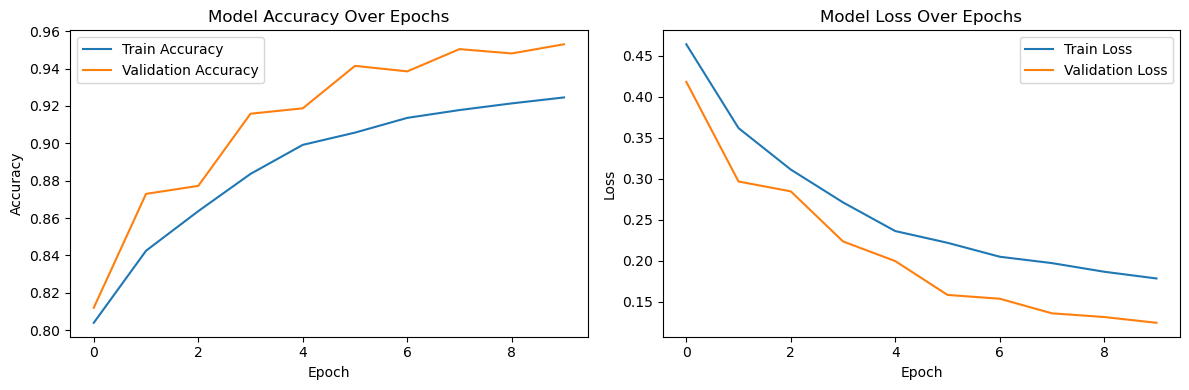

In [11]:
plt.figure(figsize=(12, 4))

# 🔹 Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# 🔹 Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()